### Data pre-processing notebook for classification data.

In [1]:
import pandas as pd
import seaborn as sns
import numpy as np

from imblearn.under_sampling import TomekLinks
from sklearn.ensemble import IsolationForest

In [2]:
df = pd.read_csv("credit_group_classification.csv")

In [3]:
df.describe()

,Delay_from_due_date,Num_of_Delayed_Payment,Num_Credit_Inquiries,Credit_Utilization_Ratio,Credit_History_Age,Amount_invested_monthly,Monthly_Balance,Age,Annual_Income,Num_Bank_Accounts,Num_Credit_Card,Interest_Rate,Num_of_Loan,Monthly_Inhand_Salary,Changed_Credit_Limit,Outstanding_Debt,Total_EMI_per_month
count,99960.000000,99960.000000,99960.000000,99960.000000,99960.000000,99960.000000,99960.000000,99960.000000,99960.000000,99960.000000,99960.000000,99960.000000,99960.000000,99960.000000,99960.000000,99960.000000,99960.000000
mean,21.095718,13.336345,5.774570,32.284544,221.122819,193.665219,403.445100,33.269228,50498.704153,5.368868,5.532853,14.535174,3.533974,4196.814288,10.396953,1426.514966,105.565802
std,14.827414,6.269964,3.862224,5.116888,99.696084,194.782737,214.387092,10.762371,38294.243161,2.591668,2.067698,8.741047,2.446156,3186.518163,6.510846,1155.252504,125.820983
min,0.000000,0.000000,0.000000,20.000000,1.000000,0.000000,0.007760,14.000000,7005.930000,0.000000,0.000000,1.000000,0.000000,303.645417,0.500000,0.230000,0.000000
25%,10.000000,9.000000,3.000000,28.052051,144.000000,73.708522,270.317007,24.000000,19338.480000,3.000000,4.000000,7.000000,2.000000,1626.594167,5.500000,566.080000,29.054273
50%,18.000000,14.000000,5.000000,32.305470,219.000000,129.342067,337.237873,33.000000,36996.830000,5.000000,5.000000,13.000000,3.000000,3091.386667,9.340000,1166.470000,66.058063
75%,28.000000,18.000000,8.000000,36.496305,302.000000,234.323706,471.904834,42.000000,71681.400000,7.000000,7.000000,20.000000,5.000000,5957.715000,14.680000,1948.200000,145.584994
max,67.000000,28.000000,29.000000,50.000000,404.000000,1977.326102,1602.040519,56.000000,179987.280000,10.000000,11.000000,34.000000,9.000000,15204.633333,29.980000,4998.070000,1779.103254


In [4]:
df

,Delay_from_due_date,Num_of_Delayed_Payment,Num_Credit_Inquiries,Credit_Utilization_Ratio,Credit_History_Age,Payment_of_Min_Amount,Amount_invested_monthly,Monthly_Balance,Credit_Score,Credit_Mix,...,Age,Annual_Income,Num_Bank_Accounts,Num_Credit_Card,Interest_Rate,Num_of_Loan,Monthly_Inhand_Salary,Changed_Credit_Limit,Outstanding_Debt,Total_EMI_per_month
0,3.0,7.0,4.0,26.822620,265.0,No,80.415295,312.494089,Good,Good,...,23.0,19114.12,3.0,4.0,3.0,4.0,1824.843333,11.27,809.98,49.574949
1,3.0,7.0,4.0,31.944960,265.0,No,118.280222,284.629162,Good,Good,...,23.0,19114.12,3.0,4.0,3.0,4.0,1824.843333,11.27,809.98,49.574949
2,3.0,7.0,4.0,28.609352,267.0,No,81.699521,331.209863,Good,Good,...,23.0,19114.12,3.0,4.0,3.0,4.0,1824.843333,11.27,809.98,49.574949
3,5.0,4.0,4.0,31.377862,268.0,No,199.458074,223.451310,Good,Good,...,23.0,19114.12,3.0,4.0,3.0,4.0,1824.843333,11.27,809.98,49.574949
4,6.0,4.0,4.0,24.797347,269.0,No,41.420153,341.489231,Good,Good,...,23.0,19114.12,3.0,4.0,3.0,4.0,1824.843333,11.27,809.98,49.574949
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99955,23.0,7.0,3.0,34.663572,378.0,No,60.971333,479.866228,Poor,Good,...,25.0,39628.99,4.0,6.0,7.0,2.0,3359.415833,11.50,502.38,35.104023
99956,18.0,7.0,3.0,40.565631,379.0,No,54.185950,496.651610,Poor,Good,...,25.0,39628.99,4.0,6.0,7.0,2.0,3359.415833,11.50,502.38,35.104023
99957,27.0,6.0,3.0,41.255522,380.0,No,24.028477,516.809083,Poor,Good,...,25.0,39628.99,4.0,6.0,7.0,2.0,3359.415833,11.50,502.38,35.104023
99958,20.0,6.0,3.0,33.638208,381.0,No,251.672582,319.164979,Standard,Good,...,25.0,39628.99,4.0,6.0,7.0,2.0,3359.415833,11.50,502.38,35.104023


### This dataset has quite many categoricals, need to convert everything to numeric correctly

In [5]:
df['Credit_Mix'].value_counts()

Credit_Mix
Standard    45832
Good        30360
Bad         23768
Name: count, dtype: int64

In [6]:
# seems like an ordinal category
mix_mapping = {'Bad': 0, 'Standard': 1, 'Good': 2}
df['Credit_Mix'] = df['Credit_Mix'].map(mix_mapping)

In [7]:
df['Credit_Score'].value_counts()

Credit_Score
Standard    53149
Poor        28988
Good        17823
Name: count, dtype: int64

In [8]:
# seems like an ordinal category
score_mapping = {'Poor': 0, 'Standard': 1, 'Good': 2}
df['Credit_Score'] = df['Credit_Score'].map(score_mapping)

In [9]:
df['Payment_of_Min_Amount'].value_counts()

Payment_of_Min_Amount
Yes    52326
No     35628
NM     12006
Name: count, dtype: int64

In [10]:
df['Payment_Behaviour'].value_counts()

Payment_Behaviour
Low_spent_Small_value_payments      33912
High_spent_Medium_value_payments    26728
High_spent_Large_value_payments     16744
Low_spent_Medium_value_payments     10304
High_spent_Small_value_payments      6512
Low_spent_Large_value_payments       5760
Name: count, dtype: int64

In [11]:
# this makes multiple columns with the variable (Separate for yes/no)
from sklearn.preprocessing import OneHotEncoder
variables = ['Payment_of_Min_Amount', 'Payment_Behaviour']

# use encoder
encoder = OneHotEncoder(sparse_output=False).set_output(transform="pandas")
one_hot_encoded = encoder.fit_transform(df[variables]).astype(int)
df = pd.concat([df,one_hot_encoded],axis=1).drop(columns=variables)

In [12]:
df.head()

,Delay_from_due_date,Num_of_Delayed_Payment,Num_Credit_Inquiries,Credit_Utilization_Ratio,Credit_History_Age,Amount_invested_monthly,Monthly_Balance,Credit_Score,Credit_Mix,Age,...,Total_EMI_per_month,Payment_of_Min_Amount_NM,Payment_of_Min_Amount_No,Payment_of_Min_Amount_Yes,Payment_Behaviour_High_spent_Large_value_payments,Payment_Behaviour_High_spent_Medium_value_payments,Payment_Behaviour_High_spent_Small_value_payments,Payment_Behaviour_Low_spent_Large_value_payments,Payment_Behaviour_Low_spent_Medium_value_payments,Payment_Behaviour_Low_spent_Small_value_payments
0,3.0,7.0,4.0,26.822620,265.0,80.415295,312.494089,2,2,23.0,...,49.574949,0,1,0,0,1,0,0,0,0
1,3.0,7.0,4.0,31.944960,265.0,118.280222,284.629162,2,2,23.0,...,49.574949,0,1,0,0,1,0,0,0,0
2,3.0,7.0,4.0,28.609352,267.0,81.699521,331.209863,2,2,23.0,...,49.574949,0,1,0,0,1,0,0,0,0
3,5.0,4.0,4.0,31.377862,268.0,199.458074,223.451310,2,2,23.0,...,49.574949,0,1,0,0,1,0,0,0,0
4,6.0,4.0,4.0,24.797347,269.0,41.420153,341.489231,2,2,23.0,...,49.574949,0,1,0,0,1,0,0,0,0


In [13]:
# remove one option from each variable (small optimization)
df = df.drop(['Payment_Behaviour_Low_spent_Small_value_payments', "Payment_of_Min_Amount_NM"], axis=1)

<Axes: >

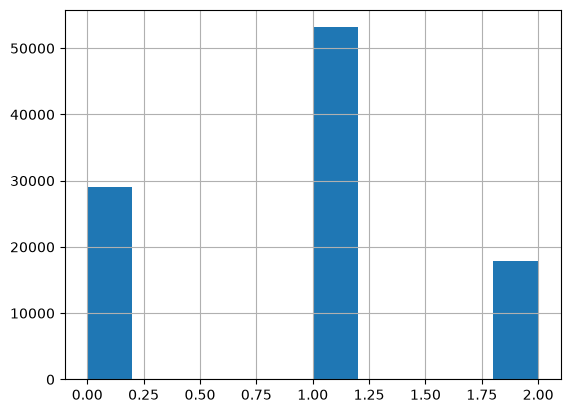

In [14]:
df['Credit_Score'].hist()

### From this point onward, these are optional dataset optimization steps

### Optimization 1: TomekLinks for overlap removal

Class distribution before overlap removal:
Credit_Score
1    53149
0    28988
2    17823
Name: count, dtype: int64
Class distribution AFTER overlap removal:
Credit_Score
1    45912
0    24800
2    17823
Name: count, dtype: int64


<Axes: >

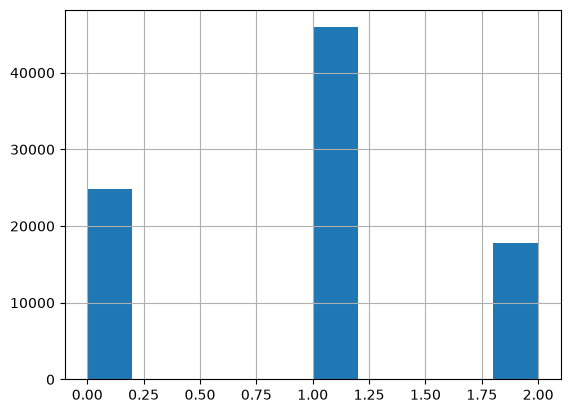

In [15]:
target = "Credit_Score"
tomek = TomekLinks()

# Display new class distribution
print("Class distribution before overlap removal:")
print(df[target].value_counts())

# X/y -split
X = df.drop(target, axis=1)
y = df[target]

# create new resampled versions of X and y
X, y = tomek.fit_resample(X, y)

# re-create a new DataFrame
df = pd.DataFrame(X, columns=X.columns)
df[target] = y

# Display new class distribution
print("Class distribution AFTER overlap removal:")
print(df[target].value_counts())

# visualize final distribution
df[target].hist()

### Optimization 2: Isolation Forest for outlier removal

In [16]:
# can process the whole dataset 
# and compares variables to each other instead
# of focusing on outliers on a single variable
from sklearn.ensemble import IsolationForest
import pandas as pd

# adjust the contamination rate as you see fit
# for example, if you expect 5% of the data to be outliers
# you can use 0.05 etc. 

# basically, this is how aggressive Isolation Forest will be
# increase if you think you need to detect more outliers
# decrease if you need less outliers
iso = IsolationForest(contamination=0.07) 

# REMEMBER! Isolation Forest is a machine learning algorithm
# => ALL VARIABLES HAVE TO BE NUMERIC AT THIS POINT

# fit isolation forest
y_pred = iso.fit_predict(df)

# separate outliers and inliers into separate DataFrames
outliers = df[y_pred != 1]
inliers = df[y_pred == 1]

print(f"Inliers: {len(inliers)}")
print(f"Outliers: {len(outliers)}")

# we want to keep only the inliers (non-noisy data)
# replace the current DataFrame with the inliers
df = inliers

Inliers: 82337
Outliers: 6198


**Another optimization idea => use sampling to reduce the amount of Credit_Score == 1**

<Axes: >

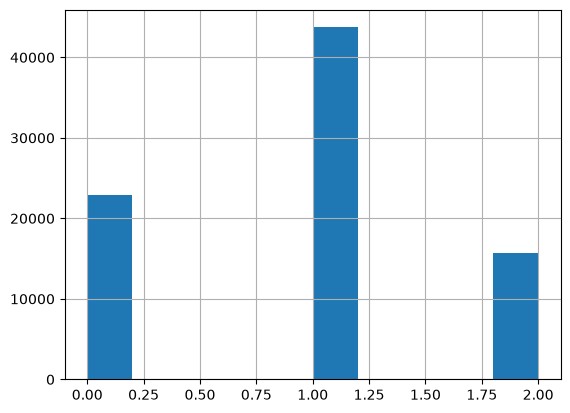

In [17]:
df['Credit_Score'].hist()

In [18]:
# save this cleaned version to a csv-file
df.to_csv("processed_classification_credit_group.csv", index=None)